# Vision — Semi-supervised (sedikit gambar berlabel, banyak tanpa label)
**Kapan dipakai:** hanya sebagian kecil gambar yang berlabel. Gambar tanpa label bisa datang
sebagai (a) baris CSV dengan label kosong, dan/atau (b) folder terpisah berisi gambar tanpa label.

**Langkah (self-training / pseudo-label):** latih di yang berlabel → tebak yang tanpa label →
untuk TIAP kelas, `PER_CLASS` tebakan paling yakin dijadikan label → latih ulang → ulangi
beberapa putaran. Putaran terbaik dipilih dengan validasi. Pembanding: `LabelSpreading`
(label menyebar ke tetangga terdekat di ruang embedding).

**Bentuk data yang didukung:** CSV `id,label` (label boleh kosong) + folder gambar (aktif),
folder per kelas, atau label di nama file (lihat sel alternatif), ditambah `UNLABELED_FOLDER`.

**Data demo:** `pets` (10 ras kucing/anjing, Oxford-IIIT Pet). Hanya 10% label train yang
dipakai, ditambah 300 gambar folder `tanpa_label` (ada GIF/grayscale/RGBA).

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.semi_supervised import LabelSpreading
from torch import nn
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"              # tidak ada? pakai sample_submission.csv
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
TEST_IMAGE_FOLDER = f"{DATA_FOLDER}/test"
UNLABELED_FOLDER = f"{DATA_FOLDER}/tanpa_label"   # folder gambar tanpa label, "" bila tidak ada
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "../../pretrained"
OUTPUT_FOLDER = "../../outputs/vision/semi_supervised"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar (juga kolom id di submission)
TARGET = "label"        # kolom kelas (boleh kosong untuk gambar tanpa label)
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
LABELED_FRACTION = 0.10   # HANYA DEMO: bagian label train yang dipakai
PER_CLASS = 10            # pseudo-label baru per kelas per putaran (seimbang antar kelas)
N_ROUNDS = 5
VAL_FRACTION = 0.3        # bagian data BERLABEL yang disisihkan untuk validasi
IMAGE_SIZE = 224
BATCH_SIZE = 64
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

## Baca data — bentuk 1: CSV `id,label` + folder gambar (aktif)
Baris dengan label kosong (`NaN`) otomatis dianggap gambar tanpa label.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
test["path"] = TEST_IMAGE_FOLDER + "/" + test[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape, "| test:", test.shape)
print("contoh path:", train["path"].iloc[0])
print("label kosong di CSV:", train[TARGET].isna().sum())

train: (805, 4) | test: (269, 2)
contoh path: ../../data_latihan/vision/pets/train/Siamese_24.jpg
label kosong di CSV: 0


## (Alternatif) bentuk 2: folder per kelas `train/<kelas>/*.jpg`

In [4]:
# rows = []
# for class_name in sorted(os.listdir(TRAIN_IMAGE_FOLDER)):
#     for path in sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/{class_name}/*")):
#         rows.append([os.path.basename(path), class_name, path])
# train = pd.DataFrame(rows, columns=[ID_COL, TARGET, "path"])
# test = pd.DataFrame()
# test["path"] = sorted(glob.glob(f"{TEST_IMAGE_FOLDER}/*"))
# test[ID_COL] = test["path"].apply(os.path.basename)   # cocokkan dengan format sample_submission

## (Alternatif) bentuk 3: label di nama file `Abyssinian_12.jpg`

In [5]:
# train = pd.DataFrame()
# train["path"] = sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/*"))
# train[ID_COL] = train["path"].apply(os.path.basename)
# train[TARGET] = train[ID_COL].str.rsplit("_", n=1).str[0]

## Sembunyikan sebagian besar label (HANYA DEMO, HAPUS sel ini saat lomba)
Saat lomba ganti dengan satu baris: `train["used_label"] = train[TARGET]`.

In [6]:
labeled_rows, _ = train_test_split(np.arange(len(train)), train_size=LABELED_FRACTION,
                                   random_state=SEED, stratify=train[TARGET])
used_labels = np.full(len(train), None, dtype=object)
used_labels[labeled_rows] = train[TARGET].to_numpy()[labeled_rows]
train["used_label"] = used_labels

## Gabungkan gambar dari folder tanpa label
Semua gambar (train berlabel, train tanpa label, folder tanpa label) masuk satu tabel `pool`.

In [7]:
pool = train[["path", "used_label"]].copy()
if UNLABELED_FOLDER != "":
    extra = pd.DataFrame()
    extra["path"] = sorted(glob.glob(f"{UNLABELED_FOLDER}/*"))
    extra["used_label"] = None
    pool = pd.concat([pool, extra], ignore_index=True)
print("berlabel:", pool["used_label"].notna().sum(),
      "| tanpa label:", pool["used_label"].isna().sum())
print(pool["used_label"].value_counts())

berlabel: 80 | tanpa label: 1025
used_label
Abyssinian                    15
beagle                        13
pug                           12
Persian                       11
Siamese                        8
shiba_inu                      7
Bengal                         5
yorkshire_terrier              4
Egyptian_Mau                   3
staffordshire_bull_terrier     2
Name: count, dtype: int64


## Gambar → tensor → embedding ResNet50 beku
`convert("RGB")` menyamakan GIF/grayscale/RGBA; `ImageOps.fit` memotong tengah lalu mengecilkan.

In [8]:
def load_images(paths):
    images = np.zeros((len(paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for i, path in enumerate(paths):
        image = Image.open(path).convert("RGB")
        images[i] = ImageOps.fit(image, (IMAGE_SIZE, IMAGE_SIZE))
    return torch.tensor(images).permute(0, 3, 1, 2)     # (jumlah, 3, tinggi, lebar)


def embed(images):
    batches = []
    with torch.no_grad():
        for start in range(0, len(images), BATCH_SIZE):
            batch = (images[start:start + BATCH_SIZE].float() / 255 - MEAN) / STD
            batches.append(backbone(batch.to(DEVICE)).cpu())
    return torch.cat(batches).numpy()


backbone = models.resnet50(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE)
backbone.eval()
X_pool = embed(load_images(pool["path"]))
X_test = embed(load_images(test["path"]))
print("pool:", X_pool.shape, "| test:", X_test.shape)

pool: (1105, 2048) | test: (269, 2048)


## Validasi dari data berlabel
`VAL_FRACTION` data berlabel disisihkan (tidak dilatih, tidak diberi pseudo-label) untuk
memilih putaran. Kelas dengan label sangat sedikit? Turunkan `VAL_FRACTION` ke 0.2.

In [9]:
labeled = np.where(pool["used_label"].notna())[0]
val_rows, _ = train_test_split(labeled, train_size=VAL_FRACTION, random_state=SEED,
                               stratify=pool["used_label"].iloc[labeled])
X_val = X_pool[val_rows]
y_val = pool["used_label"].iloc[val_rows].astype(str)
is_val = np.zeros(len(pool), dtype=bool)
is_val[val_rows] = True
print("validasi:", len(val_rows), "| berlabel untuk latih:", len(labeled) - len(val_rows))

validasi: 24 | berlabel untuk latih: 56


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai. Model harus punya `predict_proba`.

In [10]:
model = make_pipeline(Normalizer(), LogisticRegression(C=10, max_iter=3000))
# model = KNeighborsClassifier(n_neighbors=5, metric="cosine")

## Self-training
Putaran 0 = hanya label asli (baseline). Tiap putaran menambah `PER_CLASS` pseudo-label per
kelas. Kenapa per kelas, bukan "semua yang peluangnya ≥ 0.9"? Ambang tetap membuat kelas yang
mudah dapat ratusan label baru dan kelas sulit hampir nol → model makin berat sebelah (di data
demo skor test malah turun 0.77 → 0.67). `clone(model)` = salinan model yang belum dilatih.
Validasi kecil membuat pilihan putaran kasar; kalau validasi tidak naik, putaran 0 = aman.

In [11]:
def pick_confident(probabilities, classes):
    guesses = classes[probabilities.argmax(axis=1)]
    confidence = probabilities.max(axis=1)
    picked = []
    for class_name in classes:
        rows = np.where(guesses == class_name)[0]
        picked.extend(rows[np.argsort(-confidence[rows])][:PER_CLASS])
    return np.array(picked, dtype=int), guesses


working_labels = pool["used_label"].to_numpy().copy()
working_labels[is_val] = None
round_models = []
val_scores = []
label_counts = []
for round_number in range(N_ROUNDS + 1):
    has_label = pd.notna(working_labels)
    round_model = clone(model)
    round_model.fit(X_pool[has_label], working_labels[has_label].astype(str))
    round_models.append(round_model)
    val_scores.append(f1_score(y_val, round_model.predict(X_val), average="macro"))
    label_counts.append(has_label.sum())
    # pseudo-label: baris tanpa label (bukan validasi), PER_CLASS paling yakin per kelas
    unlabeled_rows = np.where(~has_label & ~is_val)[0]
    if len(unlabeled_rows) == 0:
        break
    probabilities = round_model.predict_proba(X_pool[unlabeled_rows])
    picked, guesses = pick_confident(probabilities, round_model.classes_)
    working_labels[unlabeled_rows[picked]] = guesses[picked]

## Riwayat dan kurva skor validasi vs putaran
Validasi kecil (puluhan gambar) cepat mentok di 1.0; bila seri, dipilih putaran paling awal.

putaran terbaik menurut validasi: 2
   round  n_labels  f1_val
0      0        56  0.8444
1      1       156  0.9556
2      2       256  1.0000
3      3       356  1.0000
4      4       456  1.0000
5      5       556  1.0000


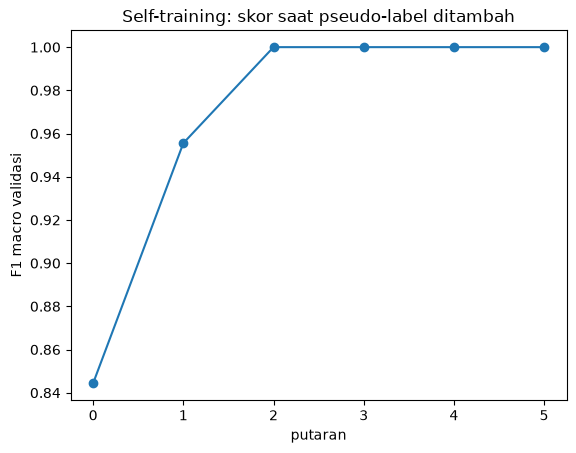

In [12]:
history = pd.DataFrame()
history["round"] = range(len(val_scores))
history["n_labels"] = label_counts
history["f1_val"] = val_scores
best_round = int(np.argmax(val_scores))
print("putaran terbaik menurut validasi:", best_round)
print(history.round(4))
plt.plot(history["round"], history["f1_val"], marker="o")
plt.xlabel("putaran")
plt.ylabel("F1 macro validasi")
plt.title("Self-training: skor saat pseudo-label ditambah")
plt.savefig(f"{OUTPUT_FOLDER}/kurva.png", dpi=120, bbox_inches="tight")
plt.show()

## Pembanding: LabelSpreading
Label kosong (dan validasi) diberi -1. Label menyebar ke 20 tetangga terdekat. `Normalizer`
(panjang vektor = 1) penting: dengan `StandardScaler` skor test demo hanya 0.46.

In [13]:
class_names = sorted(pool["used_label"].dropna().unique())
spread_labels = np.full(len(pool), -1)
for number, name in enumerate(class_names):
    spread_labels[pool["used_label"].to_numpy() == name] = number
spread_labels[is_val] = -1

scaler = Normalizer().fit(X_pool)
spread = LabelSpreading(kernel="knn", n_neighbors=20, max_iter=200)
spread.fit(scaler.transform(X_pool), spread_labels)
spread_val = np.array(class_names)[spread.predict(scaler.transform(X_val))]
spread_test = np.array(class_names)[spread.predict(scaler.transform(X_test))]
print("F1 validasi LabelSpreading:", round(f1_score(y_val, spread_val, average="macro"), 4))
print("F1 validasi self-training :", round(val_scores[best_round], 4))

F1 validasi LabelSpreading: 0.88
F1 validasi self-training : 1.0


## Submission (model dari putaran terbaik menurut validasi)

In [14]:
model = round_models[best_round]
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission[ID_COL] = test[ID_COL]
submission[TARGET] = predictions
submission.to_csv(f"{OUTPUT_FOLDER}/submission.csv", index=False)
print(submission.shape)
submission.head()

(269, 2)


,id,label
0,test_0001.jpg,pug
1,test_0002.jpg,Egyptian_Mau
2,test_0003.jpg,shiba_inu
3,test_0004.jpg,Abyssinian
4,test_0005.jpg,Siamese


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Skor test tiap putaran: apakah putaran pilihan validasi memang bagus? Baris terakhir =
batas atas bila SEMUA label train dipakai.

In [15]:
test_key = pd.read_csv(TEST_KEY_CSV)[TARGET]
test_scores = []
for round_model in round_models:
    test_scores.append(f1_score(test_key, round_model.predict(X_test), average="macro"))
history["f1_test"] = test_scores
print(history.round(4))
print("F1 test LabelSpreading:", round(f1_score(test_key, spread_test, average="macro"), 4))
full_model = clone(model)
full_model.fit(X_pool[:len(train)], train[TARGET])
print("F1 test semua label:", round(f1_score(test_key, full_model.predict(X_test),
                                             average="macro"), 4))

   round  n_labels  f1_val  f1_test
0      0        56  0.8444   0.8497
1      1       156  0.9556   0.9715
2      2       256  1.0000   0.9691
3      3       356  1.0000   0.9626
4      4       456  1.0000   0.9594
5      5       556  1.0000   0.9571
F1 test LabelSpreading: 0.903


F1 test semua label: 0.9836


## Masalah umum
- **Skor turun tiap putaran:** pseudo-label banyak yang salah. Turunkan `PER_CLASS` (5)
  atau `N_ROUNDS`. Model di sel Model sebaiknya punya peluang yang masuk akal (`Normalizer`
  + LogisticRegression; dengan `StandardScaler` + `C=0.1` di data demo self-training gagal).
- **`The least populated class in y has only 1 member`:** label terlalu sedikit untuk stratify;
  turunkan `VAL_FRACTION` atau buang `stratify=`.
- **Folder tanpa label berisi kelas di luar daftar:** pseudo-label memaksanya ke kelas terdekat.
  Turunkan `PER_CLASS`, atau buang gambar yang peluang tertingginya rendah.